In [1]:
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

parts = []
for s in ["train", "val", "test"]:
    d = pd.read_csv(f"../data/splits/{s}.csv")
    d["split"] = s
    parts.append(d)
df = pd.concat(parts, ignore_index=True)
df["path"] = "../" + df["path"]
Path("../results/figures").mkdir(parents=True, exist_ok=True)

def load(path):
    return cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)

In [2]:
# ringkasan statistik dataset

print("Total gambar:", len(df))
print("Jumlah kelas:", df.label.nunique())
print()
print(df.split.value_counts())

Total gambar: 6538
Jumlah kelas: 27

split
train    4576
val       981
test      981
Name: count, dtype: int64


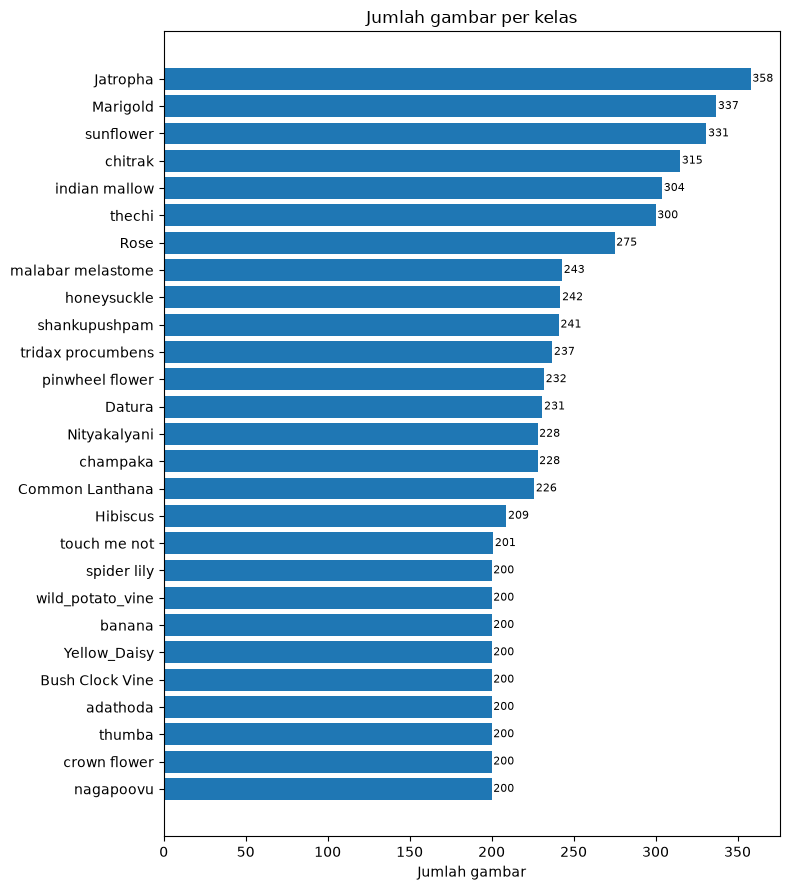

Min : 200 (nagapoovu)
Max : 358 (Jatropha)
Rasio max/min: 1.79


In [3]:
# Jumlah gambar per kelas

counts = df.label.value_counts().sort_values()

fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(counts.index, counts.values)
ax.set_xlabel("Jumlah gambar")
ax.set_title("Jumlah gambar per kelas")
for y, v in enumerate(counts.values):
    ax.text(v + 1, y, str(v), va="center", fontsize=8)
plt.tight_layout()
plt.savefig("../results/figures/class_distribution.png", dpi=200)
plt.show()

print(f"Min : {counts.min()} ({counts.idxmin()})")
print(f"Max : {counts.max()} ({counts.idxmax()})")
print(f"Rasio max/min: {counts.max() / counts.min():.2f}")

In [4]:
# ukuran dan mode gambar

sizes, modes = [], []
for p in df.path:
    with Image.open(p) as im:
        sizes.append(im.size)
        modes.append(im.mode)

print(pd.Series(sizes).value_counts())
print()
print(pd.Series(modes).value_counts())

(224, 224)    6538
Name: count, dtype: int64

RGB    6538
Name: count, dtype: int64


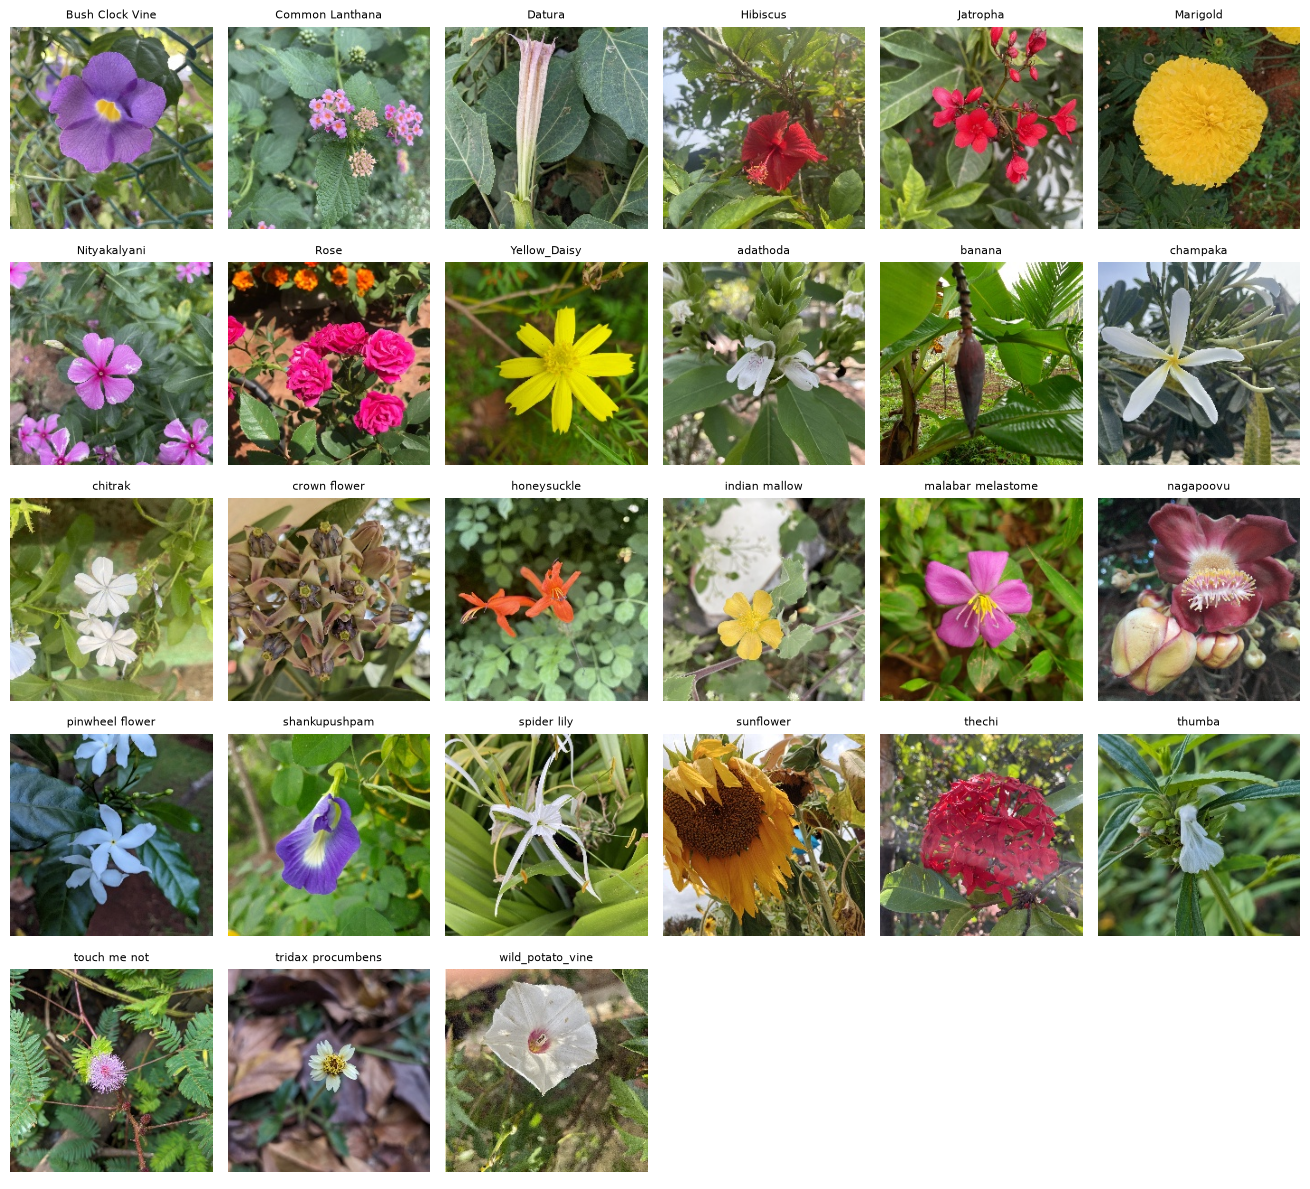

In [5]:
# contoh satu gambar per kelas

classes = sorted(df.label.unique())
cols = 6
rows = int(np.ceil(len(classes) / cols))

fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.2, rows * 2.4))
for ax in axes.ravel():
    ax.axis("off")
for ax, cls in zip(axes.ravel(), classes):
    p = df[df.label == cls].sample(1, random_state=0).path.iloc[0]
    ax.imshow(load(p))
    ax.set_title(cls, fontsize=8)
plt.tight_layout()
plt.savefig("../results/figures/class_samples.png", dpi=200)
plt.show()

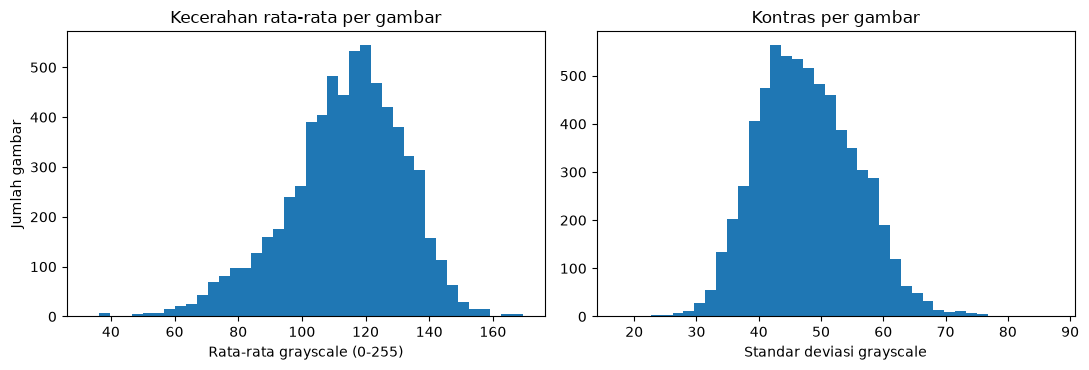

       brightness  contrast
count      6538.0    6538.0
mean        113.6      47.8
std          18.6       8.0
min          32.9      17.4
25%         103.0      42.0
50%         115.5      47.2
75%         126.7      53.2
max         169.5      87.3


In [6]:
# variasi kecerahan dan kontras gambar

brightness, contrast = [], []
for p in df.path:
    g = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2GRAY)
    brightness.append(g.mean())
    contrast.append(g.std())
df["brightness"] = brightness
df["contrast"] = contrast

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(df.brightness, bins=40)
axes[0].set_title("Kecerahan rata-rata per gambar")
axes[0].set_xlabel("Rata-rata grayscale (0-255)")
axes[0].set_ylabel("Jumlah gambar")
axes[1].hist(df.contrast, bins=40)
axes[1].set_title("Kontras per gambar")
axes[1].set_xlabel("Standar deviasi grayscale")
plt.tight_layout()
plt.savefig("../results/figures/brightness_contrast_distribution.png", dpi=200)
plt.show()

print(df[["brightness", "contrast"]].describe().round(1))

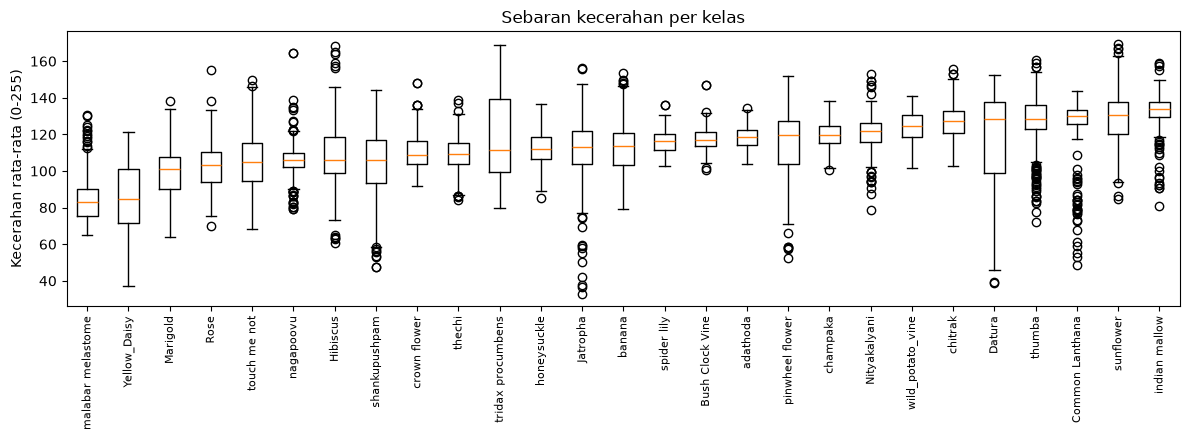

In [7]:
# kecerahan per kelas

order = df.groupby("label").brightness.median().sort_values().index

fig, ax = plt.subplots(figsize=(12, 4.5))
data = [df[df.label == c].brightness.values for c in order]
ax.boxplot(data, tick_labels=list(order))
ax.set_ylabel("Kecerahan rata-rata (0-255)")
ax.set_title("Sebaran kecerahan per kelas")
plt.xticks(rotation=90, fontsize=8)
plt.tight_layout()
plt.savefig("../results/figures/brightness_per_class.png", dpi=200)
plt.show()

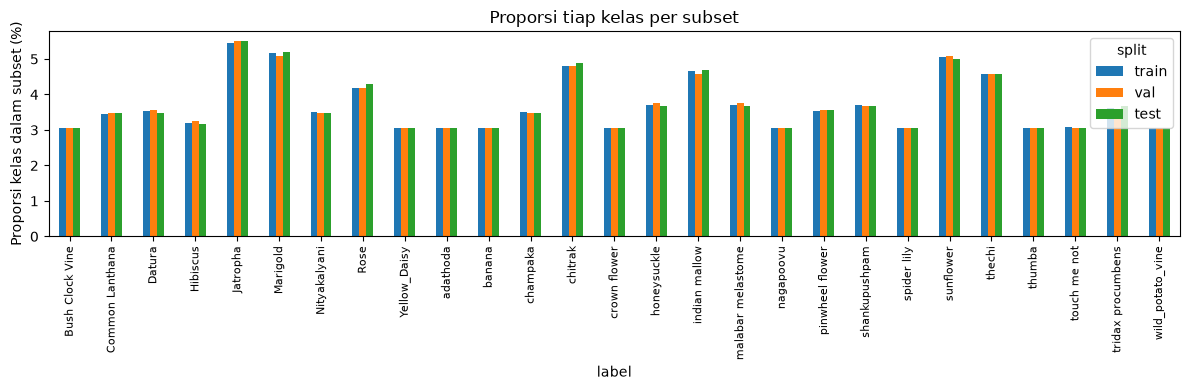

Selisih proporsi terbesar antar subset: 0.10 poin persen

split
train    140
val       30
test      30
Name: Min gambar per kelas, dtype: int64


In [8]:
# proporsi data training, validation, dan testing per kelas

prop = pd.crosstab(df.label, df.split, normalize="columns") * 100
prop = prop[["train", "val", "test"]]

prop.plot(kind="bar", figsize=(12, 4))
plt.ylabel("Proporsi kelas dalam subset (%)")
plt.title("Proporsi tiap kelas per subset")
plt.xticks(rotation=90, fontsize=8)
plt.tight_layout()
plt.savefig("../results/figures/split_distribution.png", dpi=200)
plt.show()

gap = (prop.max(axis=1) - prop.min(axis=1)).max()
print(f"Selisih proporsi terbesar antar subset: {gap:.2f} poin persen")
print()
print(pd.crosstab(df.label, df.split)[["train", "val", "test"]].min().rename("Min gambar per kelas"))